In [14]:
print("hello")

hello


In [15]:
import pandas as pd
df = pd.read_csv(r"C:\Python_Project\AB_NYC_2019.csv")
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n

In [17]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [18]:
print("price = 0:", (df["price"] == 0).sum())
print("price > 1000:", (df["price"] > 1000).sum())
print("minimum_nights > 365:", (df["minimum_nights"] > 365).sum())

price = 0: 11
price > 1000: 239
minimum_nights > 365: 14


In [19]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate ids:", df["id"].duplicated().sum())

Duplicate rows: 0
Duplicate ids: 0


In [20]:
print("Before:", df.shape)

df_clean = df.copy()
df_clean["name"] = df_clean["name"].fillna("Unknown")
df_clean["host_name"] = df_clean["host_name"].fillna("Unknown")
df_clean["reviews_per_month"] = df_clean["reviews_per_month"].fillna(0)
df_clean["last_review"] = pd.to_datetime(df_clean["last_review"])

df_clean = df_clean[(df_clean["price"] > 0) & (df_clean["price"] <= 1000)]
df_clean = df_clean[df_clean["minimum_nights"] <= 365]

print("After:", df_clean.shape)

Before: (48895, 16)
After: (48631, 16)


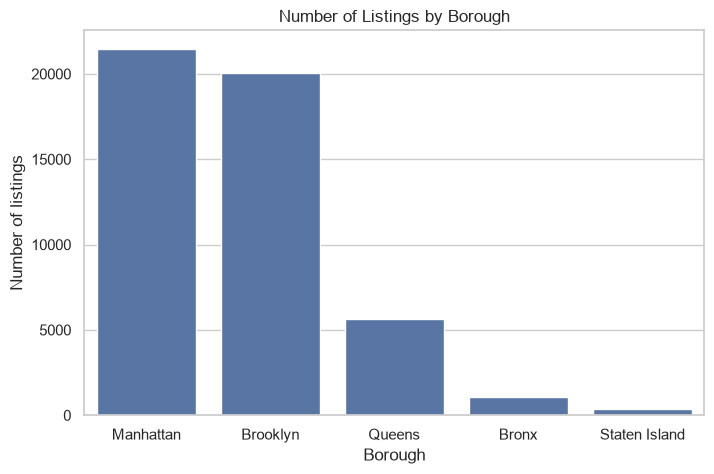

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

counts = df_clean["neighbourhood_group"].value_counts()
plt.figure(figsize=(8, 5))
sns.barplot(x=counts.index, y=counts.values)
plt.title("Number of Listings by Borough")
plt.xlabel("Borough")
plt.ylabel("Number of listings")
plt.savefig("01_listings_by_borough.png", bbox_inches="tight")
plt.show()

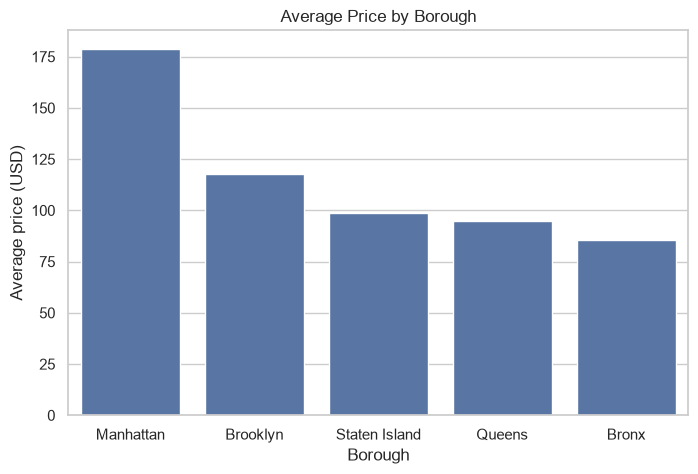

neighbourhood_group
Manhattan        178.9
Brooklyn         117.9
Staten Island     98.6
Queens            95.0
Bronx             85.4
Name: price, dtype: float64


In [22]:
avg_price = df_clean.groupby("neighbourhood_group")["price"].mean().sort_values(ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x=avg_price.index, y=avg_price.values)
plt.title("Average Price by Borough")
plt.xlabel("Borough")
plt.ylabel("Average price (USD)")
plt.savefig("02_avg_price_by_borough.png", bbox_inches="tight")
plt.show()
print(avg_price.round(1))

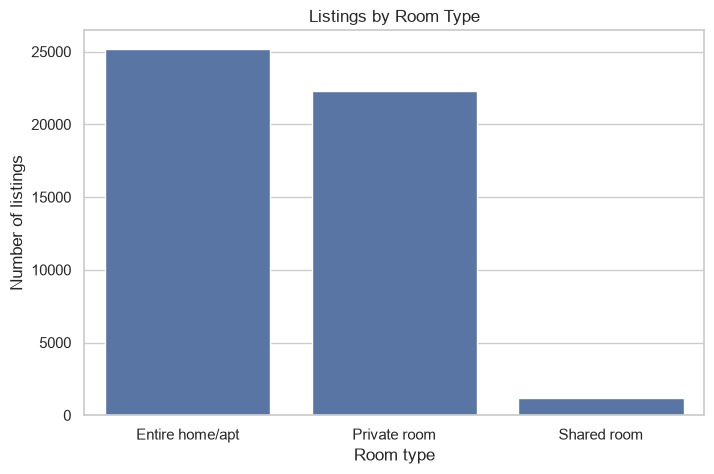

room_type
Entire home/apt    194.6
Private room        84.8
Shared room         67.7
Name: price, dtype: float64


In [23]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x="room_type", order=df_clean["room_type"].value_counts().index)
plt.title("Listings by Room Type")
plt.xlabel("Room type")
plt.ylabel("Number of listings")
plt.savefig("03_room_type_counts.png", bbox_inches="tight")
plt.show()
print(df_clean.groupby("room_type")["price"].mean().round(1))

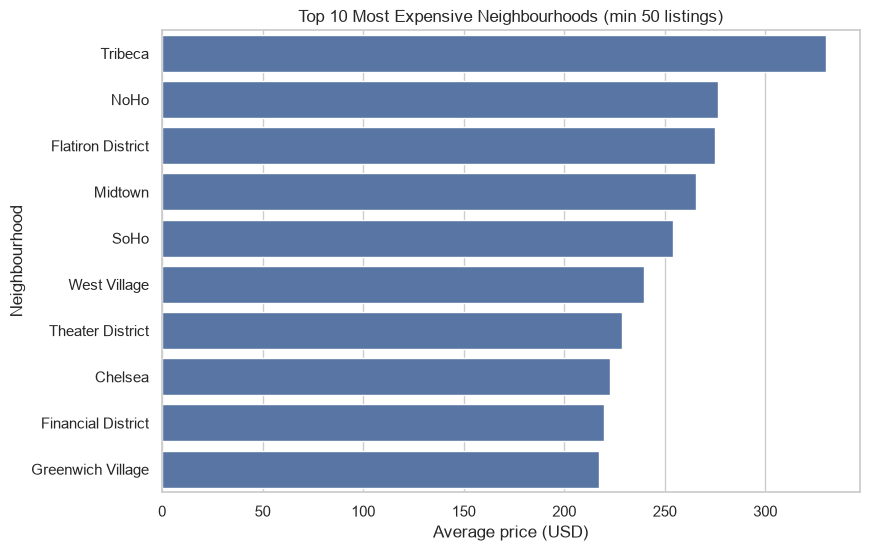

In [24]:
g = df_clean.groupby("neighbourhood")["price"].agg(["mean", "count"])
g = g[g["count"] >= 50].sort_values("mean", ascending=False).head(10)

plt.figure(figsize=(9, 6))
sns.barplot(x=g["mean"], y=g.index)
plt.title("Top 10 Most Expensive Neighbourhoods (min 50 listings)")
plt.xlabel("Average price (USD)")
plt.ylabel("Neighbourhood")
plt.savefig("04_top_neighbourhoods.png", bbox_inches="tight")
plt.show()

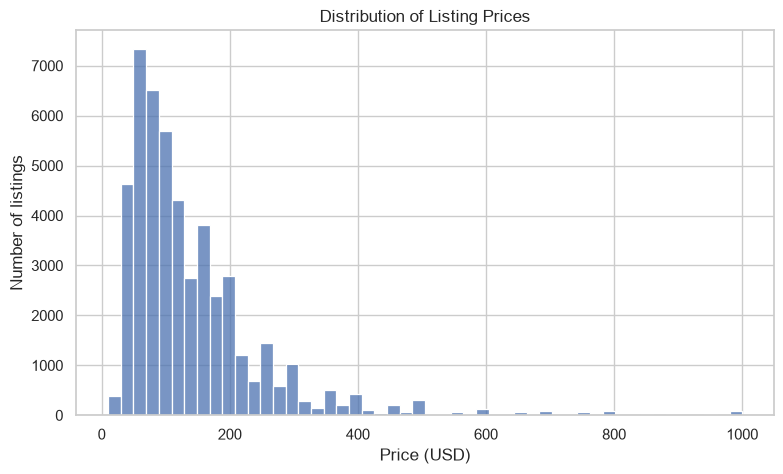

Mean: 141.3
Median: 105.0


In [25]:
plt.figure(figsize=(9, 5))
sns.histplot(df_clean["price"], bins=50)
plt.title("Distribution of Listing Prices")
plt.xlabel("Price (USD)")
plt.ylabel("Number of listings")
plt.savefig("05_price_distribution.png", bbox_inches="tight")
plt.show()
print("Mean:", round(df_clean["price"].mean(), 1))
print("Median:", df_clean["price"].median())

In [26]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate ids:", df["id"].duplicated().sum())

Duplicate rows: 0
Duplicate ids: 0


In [27]:
print("Before:", len(df))
print("After:", len(df_clean))
print(df_clean.groupby("neighbourhood_group")["price"].agg(["count", "mean"]).round(1))
print(df_clean["room_type"].value_counts())

Before: 48895
After: 48631
                     count   mean
neighbourhood_group              
Bronx                 1089   85.4
Brooklyn             20035  117.9
Manhattan            21482  178.9
Queens                5654   95.0
Staten Island          371   98.6
room_type
Entire home/apt    25207
Private room       22269
Shared room         1155
Name: count, dtype: int64
